# Data Validation, Cleanup, and Profiling
## Project: Health Colombia - ETL

This notebook performs validation, cleanup, and profiling of source datasets before the ETL process.

**Datasets:**
- Healthcare system affiliates by department, municipality, and regime
- Public and private healthcare facilities by care level and installed capacity

**Target star schema (5 dimensions):**
- `dim_time` - Temporal dimension
- `dim_geografia` - Unified geography (DANE codes + API Colombia enrichment: capital, surface, population, municipalities_count, phone_prefix, region_api)
- `dim_regime` - Healthcare regime
- `dim_facility` - Healthcare facility (references `sk_geografia`)
- `dim_capacity_type` - Capacity type classification

**Removed dimensions:** `dim_department`, `dim_municipality`, `dim_department_api` (consolidated into `dim_geografia`)

In [1]:
import pandas as pd
import numpy as np
import os
import sys

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)

print(f"Python: {sys.version}")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")

Python: 3.12.7 (tags/v3.12.7:0b05ead, Oct  1 2024, 03:06:41) [MSC v.1941 64 bit (AMD64)]
Pandas: 3.0.6
NumPy: 2.5.3


## 1. Data Loading

In [2]:
from pathlib import Path

# Works both from notebooks/ and the repository root.
PROJECT_DIR = Path.cwd() if (Path.cwd() / 'data' / 'raw').exists() else Path.cwd().parent
DATA_DIR = str(PROJECT_DIR / 'data' / 'raw')
AFFILIATES_FILE = 'affiliates_by_department_municipality_regime_20260906.csv'
FACILITIES_FILE = 'healthcare_facilities_by_level_capacity_20260906.csv'
print('Sources:', AFFILIATES_FILE, 'and', FACILITIES_FILE)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from src.numeric import parse_capacity


Sources: affiliates_by_department_municipality_regime_20260906.csv and healthcare_facilities_by_level_capacity_20260906.csv


In [3]:
df_affiliates = pd.read_csv(f"{DATA_DIR}/{AFFILIATES_FILE}", dtype=str)
df_facilities = pd.read_csv(f"{DATA_DIR}/{FACILITIES_FILE}", dtype=str)

print("Datasets loaded successfully")
print(f"Affiliates: {df_affiliates.shape[0]:,} rows, {df_affiliates.shape[1]} columns")
print(f"Facilities: {df_facilities.shape[0]:,} rows, {df_facilities.shape[1]} columns")

Datasets loaded successfully
Affiliates: 3,369 rows, 8 columns
Facilities: 41,427 rows, 20 columns


## 2. Exploratory Analysis - Affiliates Dataset

In [4]:
print("=" * 60)
print("DATASET: HEALTHCARE SYSTEM AFFILIATES")
print("=" * 60)

print("\nFirst 5 rows:")
df_affiliates.head()

DATASET: HEALTHCARE SYSTEM AFFILIATES

First 5 rows:


,CodDepto,Departamento,CodMunicipio,Municipio,IDRegimen,Año,Mes,NumPersonas
0,15,BOYACA,15293,GACHANTIVÁ,S,2022,4,2.194
1,23,CORDOBA,23350,LA APARTADA,E,2022,4,103
2,15,BOYACA,15681,SAN PABLO DE BORBUR,C,2022,4,761
3,68,SANTANDER,68207,CONCEPCIÓN,C,2022,4,405
4,68,SANTANDER,68820,TONA,S,2022,4,4.595


In [5]:
print("\nGeneral dataset info:")
df_affiliates.info()


General dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 3369 entries, 0 to 3368
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   CodDepto      3369 non-null   str  
 1   Departamento  3369 non-null   str  
 2   CodMunicipio  3369 non-null   str  
 3   Municipio     3369 non-null   str  
 4   IDRegimen     3369 non-null   str  
 5   Año           3369 non-null   str  
 6   Mes           3369 non-null   str  
 7   NumPersonas   3369 non-null   str  
dtypes: str(8)
memory usage: 323.6 KB


In [6]:
print("\nDescriptive statistics:")
df_affiliates.describe(include='all')


Descriptive statistics:


,CodDepto,Departamento,CodMunicipio,Municipio,IDRegimen,Año,Mes,NumPersonas
count,3369,3369,3369,3369,3369,3369,3369,3369
unique,34,34,1129,1046,4,1,1,2399
top,05,ANTIOQUIA,68684,VILLANUEVA,S,2022,4,17
freq,377,377,4,12,1124,3369,3369,9


In [7]:
print("\nData types per column:")
for col in df_affiliates.columns:
    print(f"  {col}: {df_affiliates[col].dtype} - Example: '{df_affiliates[col].iloc[0]}'")


Data types per column:
  CodDepto: str - Example: '15'
  Departamento: str - Example: 'BOYACA'
  CodMunicipio: str - Example: '15293'
  Municipio: str - Example: 'GACHANTIVÁ'
  IDRegimen: str - Example: 'S'
  Año: str - Example: '2022'
  Mes: str - Example: '4'
  NumPersonas: str - Example: '2.194'


### 2.1 Null Values - Affiliates

In [8]:
print("\nNull values per column:")
null_affiliates = df_affiliates.isnull().sum()
null_percentage = (null_affiliates / len(df_affiliates) * 100).round(2)

df_null_aff = pd.DataFrame({
    'Nulls': null_affiliates,
    'Percentage': null_percentage
})
df_null_aff[df_null_aff['Nulls'] > 0].sort_values('Percentage', ascending=False)


Null values per column:


,Nulls,Percentage


In [9]:
print("\nTotal null values:", df_affiliates.isnull().sum().sum())
print("Rows with at least one null:", df_affiliates.isnull().any(axis=1).sum())


Total null values: 0
Rows with at least one null: 0


### 2.2 Duplicates - Affiliates

In [10]:
print("\nDuplicates per column:")
for col in df_affiliates.columns:
    dup_count = df_affiliates[col].duplicated().sum()
    if dup_count > 0:
        print(f"  {col}: {dup_count:,} duplicates")


Duplicates per column:
  CodDepto: 3,335 duplicates
  Departamento: 3,335 duplicates
  CodMunicipio: 2,240 duplicates
  Municipio: 2,323 duplicates
  IDRegimen: 3,365 duplicates
  Año: 3,368 duplicates
  Mes: 3,368 duplicates
  NumPersonas: 970 duplicates


In [11]:
complete_duplicates = df_affiliates.duplicated().sum()
print(f"\nFully duplicated rows: {complete_duplicates:,}")
print(f"Percentage: {complete_duplicates/len(df_affiliates)*100:.2f}%")

if complete_duplicates > 0:
    print("\nExample of duplicated rows:")
    display(df_affiliates[df_affiliates.duplicated(keep=False)].head(10))


Fully duplicated rows: 0


Percentage: 0.00%


### 2.3 Unique Values - Affiliates

In [12]:
print("\nUnique values per column:")
for col in df_affiliates.columns:
    unique_count = df_affiliates[col].nunique()
    print(f"  {col}: {unique_count:,} unique values")


Unique values per column:
  CodDepto: 34 unique values
  Departamento: 34 unique values
  CodMunicipio: 1,129 unique values
  Municipio: 1,046 unique values
  IDRegimen: 4 unique values
  Año: 1 unique values
  Mes: 1 unique values
  NumPersonas: 2,399 unique values


In [13]:
print("\nRegime distribution:")
print(df_affiliates['IDRegimen'].value_counts())


Regime distribution:
IDRegimen
S    1124
C    1122
E    1115
I       8
Name: count, dtype: int64


In [14]:
print("\nDepartments with most affiliates:")
dept_count = df_affiliates['Departamento'].value_counts().head(10)
print(dept_count)


Departments with most affiliates:
Departamento
ANTIOQUIA             377
BOYACA                369
CUNDINAMARCA          349
SANTANDER             263
NARINO                193
TOLIMA                141
BOLIVAR               138
CAUCA                 126
VALLE                 126
NORTE DE SANTANDER    120
Name: count, dtype: int64


### 2.4 NumPersonas Analysis - Affiliates

In [15]:
print("\nNumPersonas analysis:")
print(f"  Current type: {df_affiliates['NumPersonas'].dtype}")
print(f"  Example values: {df_affiliates['NumPersonas'].head(10).tolist()}")

df_affiliates['NumPersonas_Clean'] = df_affiliates['NumPersonas'].str.replace('.', '', regex=False)
df_affiliates['NumPersonas_Clean'] = pd.to_numeric(df_affiliates['NumPersonas_Clean'], errors='coerce')

print(f"\nAfter cleanup:")
print(f"  Null values: {df_affiliates['NumPersonas_Clean'].isnull().sum()}")
print(f"  Minimum: {df_affiliates['NumPersonas_Clean'].min():,.0f}")
print(f"  Maximum: {df_affiliates['NumPersonas_Clean'].max():,.0f}")
print(f"  Average: {df_affiliates['NumPersonas_Clean'].mean():,.0f}")


NumPersonas analysis:


  Current type: str
  Example values: ['2.194', '103', '761', '405', '4.595', '839', '2.506', '1.305', '881', '144']

After cleanup:
  Null values: 0
  Minimum: 1
  Maximum: 6,410,877
  Average: 15,192


### 2.5 Visual evidence — affiliations

Totals by regime answer the business question; the histogram shows the long tail in municipal counts. The sources are snapshots, not real-time observations.

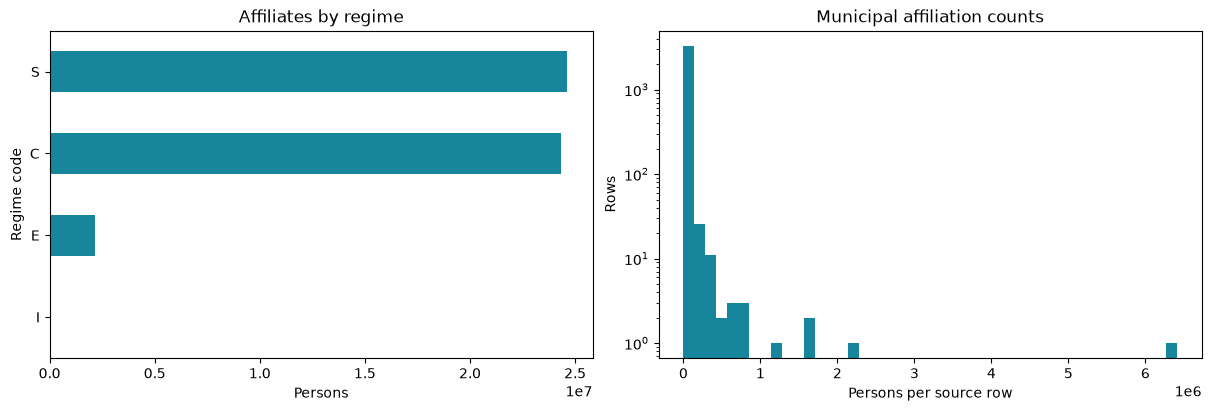

In [16]:
%matplotlib inline
import matplotlib.pyplot as plt
EVIDENCE_DIR = PROJECT_DIR / 'docs' / 'evidence' / 'profiling'
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
regime_totals = df_affiliates.groupby('IDRegimen')['NumPersonas_Clean'].sum().sort_values()
regime_totals.plot.barh(ax=axes[0], color='#17859c')
axes[0].set(title='Affiliates by regime', xlabel='Persons', ylabel='Regime code')
axes[1].hist(df_affiliates['NumPersonas_Clean'], bins=45, color='#17859c')
axes[1].set(title='Municipal affiliation counts', xlabel='Persons per source row', ylabel='Rows', yscale='log')
fig.savefig(EVIDENCE_DIR / 'eda_affiliates.png', dpi=150)
plt.show()


## 3. Exploratory Analysis - Facilities Dataset

In [17]:
print("=" * 60)
print("DATASET: PUBLIC AND PRIVATE HEALTHCARE FACILITIES")
print("=" * 60)

print("\nFirst 5 rows:")
df_facilities.head()

DATASET: PUBLIC AND PRIVATE HEALTHCARE FACILITIES

First 5 rows:


,Departamento,Municipio,Código prestador,Nombre prestador,nit IPS,num digito_verificion,naturaleza,num nivel atencion,Código sede,Número sede,nom sede IPS,Gerente,Dirección,Email,Teléfono,nom grupo capacidad,nom descripcion capacidad,num cantidad capacidad instalada,Fecha Corte,Fuente
0,Antioquia,APARTADÓ,504512253,URAMEDICOS S.A.S.,"900,497,151",1,Privada,NaN,504512253,01,URAMEDICOS,CLAUDIA CECILIA TRUJILLO GOMEZ,KR 98 # 103-29/37,uramedicos@gmail.com,8286090,SALAS,Procedimientos,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
1,Antioquia,SALGAR,564204576,ESE HOSPITAL SAN JOSE,"890,981,424",7,Pública,1,564204576,01,E.S.E. HOSPITAL SAN JOSE,CESAR AUGUSTO PARDO ROSAS,CL 32A # 33-04,secretaria@hsjsalgar.gov.co,8442020,CAMAS,TPR,2,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
2,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,"838,000,096",7,Pública,2,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CAMAS,Pediátrica,3,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
3,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,"838,000,096",7,Pública,2,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CAMAS,Adultos,4,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
4,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,"838,000,096",7,Pública,2,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CAMAS,TPR,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...


In [18]:
print("\nGeneral dataset info:")
df_facilities.info()


General dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 41427 entries, 0 to 41426
Data columns (total 20 columns):
 #   Column                            Non-Null Count  Dtype
---  ------                            --------------  -----
 0   Departamento                      41427 non-null  str  
 1   Municipio                         41427 non-null  str  
 2   Código prestador                  41427 non-null  str  
 3   Nombre prestador                  41427 non-null  str  
 4   nit IPS                           41427 non-null  str  
 5   num digito_verificion             41399 non-null  str  
 6   naturaleza                        41427 non-null  str  
 7   num nivel atencion                16161 non-null  str  
 8   Código sede                       41427 non-null  str  
 9   Número sede                       41427 non-null  str  
 10  nom sede IPS                      41427 non-null  str  
 11  Gerente                           41202 non-null  str  
 12  Dirección           

In [19]:
print("\nDescriptive statistics:")
df_facilities.describe(include='all')


Descriptive statistics:


,Departamento,Municipio,Código prestador,Nombre prestador,nit IPS,num digito_verificion,naturaleza,num nivel atencion,Código sede,Número sede,nom sede IPS,Gerente,Dirección,Email,Teléfono,nom grupo capacidad,nom descripcion capacidad,num cantidad capacidad instalada,Fecha Corte,Fuente
count,41427,41427,41427,41427,41427,41399,41427,16161,41427,41427,41427,41202,41365,41362,40116,41427,41427,41427,41427,41427
unique,38,1027,9320,8357,7915,11,3,3,10921,77,14821,9699,15196,9402,12353,7,59,195,1,1
top,Bogotá D.C,BOGOTÁ,5060600634,EMPRESA SOCIAL DEL ESTADO DEL DEPARTAMENTO DEL...,"822,006,595",1,Privada,1,1100130296,01,GLOBAL LIFE AMBULANCIAS SAS,JORGE HERNAN MOJICA MOLINARES,CALLE PRINCIPAL,gerente@subredsuroccidente.gov.co,4431790,CONSULTORIOS,Consulta Externa,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
freq,4647,4647,176,176,176,7463,25067,12588,171,27699,87,176,275,171,167,16053,14532,19663,41427,41427


In [20]:
print("\nData types per column:")
for col in df_facilities.columns:
    print(f"  {col}: {df_facilities[col].dtype} - Example: '{df_facilities[col].iloc[0]}'")


Data types per column:
  Departamento: str - Example: 'Antioquia'
  Municipio: str - Example: 'APARTADÓ'
  Código prestador: str - Example: '504512253'
  Nombre prestador: str - Example: 'URAMEDICOS S.A.S.'
  nit IPS : str - Example: '900,497,151'
  num digito_verificion: str - Example: '1'
  naturaleza: str - Example: 'Privada'
  num nivel atencion: str - Example: 'nan'
  Código sede: str - Example: '504512253'
  Número sede: str - Example: '01'
  nom sede IPS: str - Example: 'URAMEDICOS'
  Gerente: str - Example: 'CLAUDIA CECILIA TRUJILLO GOMEZ'
  Dirección: str - Example: 'KR 98 # 103-29/37'
  Email: str - Example: 'uramedicos@gmail.com'
  Teléfono: str - Example: '8286090'
  nom grupo capacidad : str - Example: 'SALAS'
  nom descripcion capacidad : str - Example: 'Procedimientos'
  num cantidad capacidad instalada: str - Example: '1'
  Fecha Corte: str - Example: 'Fecha corte REPS: Nov  5 2022  1:37PM'
  Fuente: str - Example: 'Base de datos Registro Especial de Prestadores de Ser

### 3.1 Null Values - Facilities

In [21]:
print("\nNull values per column:")
null_facilities = df_facilities.isnull().sum()
null_percentage_fac = (null_facilities / len(df_facilities) * 100).round(2)

df_null_fac = pd.DataFrame({
    'Nulls': null_facilities,
    'Percentage': null_percentage_fac
})
df_null_fac[df_null_fac['Nulls'] > 0].sort_values('Percentage', ascending=False)


Null values per column:


,Nulls,Percentage
num nivel atencion,25266,60.99
Teléfono,1311,3.16
Gerente,225,0.54
Email,65,0.16
Dirección,62,0.15
num digito_verificion,28,0.07


In [22]:
print("\nTotal null values:", df_facilities.isnull().sum().sum())
print("Rows with at least one null:", df_facilities.isnull().any(axis=1).sum())


Total null values: 26957
Rows with at least one null: 26016


### 3.2 Duplicates - Facilities

In [23]:
print("\nDuplicates per column:")
for col in df_facilities.columns:
    dup_count = df_facilities[col].duplicated().sum()
    if dup_count > 0:
        print(f"  {col}: {dup_count:,} duplicates")


Duplicates per column:
  Departamento: 41,389 duplicates
  Municipio: 40,400 duplicates
  Código prestador: 32,107 duplicates
  Nombre prestador: 33,070 duplicates
  nit IPS : 33,512 duplicates
  num digito_verificion: 41,415 duplicates
  naturaleza: 41,424 duplicates
  num nivel atencion: 41,423 duplicates
  Código sede: 30,506 duplicates
  Número sede: 41,350 duplicates
  nom sede IPS: 26,606 duplicates
  Gerente: 31,727 duplicates
  Dirección: 26,230 duplicates
  Email: 32,024 duplicates
  Teléfono: 29,073 duplicates
  nom grupo capacidad : 41,420 duplicates
  nom descripcion capacidad : 41,368 duplicates
  num cantidad capacidad instalada: 41,232 duplicates
  Fecha Corte: 41,426 duplicates
  Fuente: 41,426 duplicates


In [24]:
complete_duplicates_fac = df_facilities.duplicated().sum()
print(f"\nFully duplicated rows: {complete_duplicates_fac:,}")
print(f"Percentage: {complete_duplicates_fac/len(df_facilities)*100:.2f}%")

if complete_duplicates_fac > 0:
    print("\nExample of duplicated rows:")
    display(df_facilities[df_facilities.duplicated(keep=False)].head(10))


Fully duplicated rows: 3,145
Percentage: 7.59%

Example of duplicated rows:


,Departamento,Municipio,Código prestador,Nombre prestador,nit IPS,num digito_verificion,naturaleza,num nivel atencion,Código sede,Número sede,nom sede IPS,Gerente,Dirección,Email,Teléfono,nom grupo capacidad,nom descripcion capacidad,num cantidad capacidad instalada,Fecha Corte,Fuente
140,Antioquia,ABEJORRAL,500204360,EMPRESA SOCIAL DEL ESTADO HOSPITAL SAN JUAN DE...,"890,980,643",9,Pública,1,500204360,01,EMPRESA SOCIAL DEL ESTADO HOSPITAL SAN JUAN DE...,GABRIEL JAIME BETANCUR DUQUE,CL Circular x KR Calibío,esehsjda.subgerencia@gmail.com,8647181-8647191-8647232-,AMBULANCIAS,Básica,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
141,Antioquia,ABEJORRAL,500204360,EMPRESA SOCIAL DEL ESTADO HOSPITAL SAN JUAN DE...,"890,980,643",9,Pública,1,500204360,01,EMPRESA SOCIAL DEL ESTADO HOSPITAL SAN JUAN DE...,GABRIEL JAIME BETANCUR DUQUE,CL Circular x KR Calibío,esehsjda.subgerencia@gmail.com,8647181-8647191-8647232-,AMBULANCIAS,Básica,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
142,Antioquia,ABEJORRAL,500204360,EMPRESA SOCIAL DEL ESTADO HOSPITAL SAN JUAN DE...,"890,980,643",9,Pública,1,500204360,01,EMPRESA SOCIAL DEL ESTADO HOSPITAL SAN JUAN DE...,GABRIEL JAIME BETANCUR DUQUE,CL Circular x KR Calibío,esehsjda.subgerencia@gmail.com,8647181-8647191-8647232-,AMBULANCIAS,Básica,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
166,Antioquia,ALEJANDRÍA,502105098,ESE HOSPITAL PBRO LUIS FELIPE ARBELAEZ,"800,029,509",5,Pública,1,502105098,01,ESE HOSPITAL PBRO LUIS FELIPE ARBELAEZ,Diver Arley Lopera Castaño,KR 19 # 16-70 SANTANDER,hospitalalejandria@gmail.com,8660077,AMBULANCIAS,Básica,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
167,Antioquia,ALEJANDRÍA,502105098,ESE HOSPITAL PBRO LUIS FELIPE ARBELAEZ,"800,029,509",5,Pública,1,502105098,01,ESE HOSPITAL PBRO LUIS FELIPE ARBELAEZ,Diver Arley Lopera Castaño,KR 19 # 16-70 SANTANDER,hospitalalejandria@gmail.com,8660077,AMBULANCIAS,Básica,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
179,Antioquia,AMAGÁ,503004374,ESE HOSPITAL SAN FERNANDO,"890,906,346",1,Pública,1,503004374,01,ESE HOSPITAL SAN FERNANDO,ALEJANDRO CADAVID CADAVID,KR 52 # 51-82,hospital@eseamaga-antioquia.gov.co,8472926,AMBULANCIAS,Básica,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
180,Antioquia,AMAGÁ,503004374,ESE HOSPITAL SAN FERNANDO,"890,906,346",1,Pública,1,503004374,01,ESE HOSPITAL SAN FERNANDO,ALEJANDRO CADAVID CADAVID,KR 52 # 51-82,hospital@eseamaga-antioquia.gov.co,8472926,AMBULANCIAS,Básica,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
189,Antioquia,AMALFI,503102091,E.S.E HOSPITAL EL CARMEN,"890,982,101",8,Pública,1,503102091,01,E.S.E HOSPITAL EL CARMEN,LICINIA DEL CARMEN RAVE BERMUDEZ,CL 23 # 23 - 40 COLOMBIA,hospitalamalfi@gmail.com,5748301803,AMBULANCIAS,Básica,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
190,Antioquia,AMALFI,503102091,E.S.E HOSPITAL EL CARMEN,"890,982,101",8,Pública,1,503102091,01,E.S.E HOSPITAL EL CARMEN,LICINIA DEL CARMEN RAVE BERMUDEZ,CL 23 # 23 - 40 COLOMBIA,hospitalamalfi@gmail.com,5748301803,AMBULANCIAS,Básica,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
200,Antioquia,ANDES,503404432,EMPRESA SOCIAL DEL ESTADO HOSPITAL SAN RAFAEL,"890,980,814",1,Pública,1,503404432,01,E.S.E HOSPITAL SAN RAFAEL,CARLOS ALBERTO ARROYAVE ZULUAGA,AV MEDELLIN # 48-20,gestiondocumental@hospitaldeandes.gov.co,8417120,AMBULANCIAS,Básica,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...


### 3.3 Unique Values - Facilities

In [25]:
print("\nUnique values per column:")
for col in df_facilities.columns:
    unique_count = df_facilities[col].nunique()
    print(f"  {col}: {unique_count:,} unique values")


Unique values per column:
  Departamento: 38 unique values
  Municipio: 1,027 unique values
  Código prestador: 9,320 unique values
  Nombre prestador: 8,357 unique values
  nit IPS : 7,915 unique values
  num digito_verificion: 11 unique values
  naturaleza: 3 unique values
  num nivel atencion: 3 unique values
  Código sede: 10,921 unique values
  Número sede: 77 unique values
  nom sede IPS: 14,821 unique values
  Gerente: 9,699 unique values
  Dirección: 15,196 unique values
  Email: 9,402 unique values
  Teléfono: 12,353 unique values
  nom grupo capacidad : 7 unique values
  nom descripcion capacidad : 59 unique values
  num cantidad capacidad instalada: 195 unique values
  Fecha Corte: 1 unique values
  Fuente: 1 unique values


In [26]:
print("\nNature distribution:")
print(df_facilities['naturaleza'].value_counts())


Nature distribution:
naturaleza
Privada    25067
Pública    16174
Mixta        186
Name: count, dtype: int64


In [27]:
print("\nCare level distribution:")
print(df_facilities['num nivel atencion'].value_counts())


Care level distribution:
num nivel atencion
1    12588
2     2424
3     1149
Name: count, dtype: int64


### 3.4 Installed Capacity Analysis - Facilities

In [28]:
print("\nInstalled capacity analysis:")
df_facilities['capacity_clean'] = parse_capacity(df_facilities['num cantidad capacidad instalada'])

print(f"  Null values: {df_facilities['capacity_clean'].isnull().sum()}")
print(f"  Minimum: {df_facilities['capacity_clean'].min():,.0f}")
print(f"  Maximum: {df_facilities['capacity_clean'].max():,.0f}")
print(f"  Average: {df_facilities['capacity_clean'].mean():,.2f}")


Installed capacity analysis:
  Null values: 0
  Minimum: 1
  Maximum: 1,000
  Average: 5.30


In [29]:
print("\nCapacity group distribution:")
print(df_facilities['nom grupo capacidad '].value_counts())


Capacity group distribution:
nom grupo capacidad 
CONSULTORIOS    16053
SALAS            7597
CAMAS            6738
AMBULANCIAS      5340
CAMILLAS         4409
UNIDAD MOVIL      694
SILLAS            596
Name: count, dtype: int64


### 3.5 Visual evidence — missing attributes

Missingness is concentrated in optional care-level/contact fields. The plot motivates explicit completeness checks on essential identity/capacity attributes rather than a blanket rejection of every optional null.

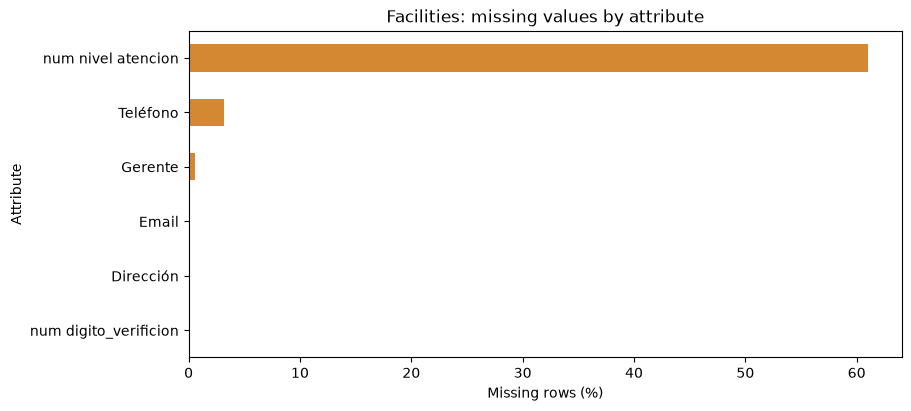

In [30]:
missing_pct = (df_facilities.isna().mean() * 100).sort_values()
missing_pct = missing_pct[missing_pct > 0]
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
missing_pct.plot.barh(ax=ax, color='#d48832')
ax.set(title='Facilities: missing values by attribute', xlabel='Missing rows (%)', ylabel='Attribute')
fig.savefig(EVIDENCE_DIR / 'eda_facilities_nulls.png', dpi=150)
plt.show()


## 4. Data Quality Summary

In [31]:
print("=" * 60)
print("DATA QUALITY SUMMARY")
print("=" * 60)

print("\nAFFILIATES:")
print(f"  Total records: {len(df_affiliates):,}")
print(f"  Complete duplicates: {df_affiliates.duplicated().sum():,}")
print(f"  Total null values: {df_affiliates.isnull().sum().sum():,}")
print(f"  Columns: {list(df_affiliates.columns)}")

print("\nFACILITIES:")
print(f"  Total records: {len(df_facilities):,}")
print(f"  Complete duplicates: {df_facilities.duplicated().sum():,}")
print(f"  Total null values: {df_facilities.isnull().sum().sum():,}")
print(f"  Columns: {list(df_facilities.columns)}")

DATA QUALITY SUMMARY

AFFILIATES:
  Total records: 3,369
  Complete duplicates: 0
  Total null values: 0
  Columns: ['CodDepto', 'Departamento', 'CodMunicipio', 'Municipio', 'IDRegimen', 'Año', 'Mes', 'NumPersonas', 'NumPersonas_Clean']

FACILITIES:
  Total records: 41,427
  Complete duplicates: 3,145
  Total null values: 26,957
  Columns: ['Departamento', 'Municipio', 'Código prestador', 'Nombre prestador', 'nit IPS ', 'num digito_verificion', 'naturaleza', 'num nivel atencion', 'Código sede', 'Número sede', 'nom sede IPS', 'Gerente', 'Dirección', 'Email', 'Teléfono', 'nom grupo capacidad ', 'nom descripcion capacidad ', 'num cantidad capacidad instalada', 'Fecha Corte', 'Fuente', 'capacity_clean']


## 5. Unified Geography Dimension (dim_geografia)

The old schema used three separate geography dimensions (`dim_department`, `dim_municipality`, `dim_department_api`). These have been consolidated into a single **`dim_geografia`** dimension that combines:

- **DANE codes**: `cod_depto`, `cod_municipio` (from source datasets)
- **API Colombia enrichment**:
  - `capital` - Department capital name
  - `surface` - Surface area (km²)
  - `population` - Total population
  - `municipalities_count` - Number of municipalities in the department
  - `phone_prefix` - Telephone prefix
  - `region_api` - Region classification from API Colombia

The `dim_facility` table references `dim_geografia` via `sk_geografia` (instead of the old `sk_municipality`).

**Removed dimensions:** `dim_department`, `dim_municipality`, `dim_department_api`

## 6. Data Cleanup

In [32]:
print("=" * 60)
print("CLEANUP PROCESS")
print("=" * 60)

df_affiliates_clean = df_affiliates.copy()
df_facilities_clean = df_facilities.copy()

CLEANUP PROCESS


### 6.1 Cleanup - Affiliates

In [33]:
print("\nAffiliates dataset cleanup:")
print(f"  Initial records: {len(df_affiliates_clean):,}")

# Remove temporary column
df_affiliates_clean = df_affiliates_clean.drop(columns=['NumPersonas_Clean'])

# Clean NumPersonas
df_affiliates_clean['NumPersonas'] = df_affiliates_clean['NumPersonas'].str.replace('.', '', regex=False)
df_affiliates_clean['NumPersonas'] = pd.to_numeric(df_affiliates_clean['NumPersonas'], errors='coerce').fillna(0).astype(int)

# Convert numeric types
df_affiliates_clean['Año'] = df_affiliates_clean['Año'].astype(int)
df_affiliates_clean['Mes'] = df_affiliates_clean['Mes'].astype(int)

# Remove records with 0 affiliates
df_affiliates_clean = df_affiliates_clean[df_affiliates_clean['NumPersonas'] > 0]

# Remove duplicates
df_affiliates_clean = df_affiliates_clean.drop_duplicates()

print(f"  Final records: {len(df_affiliates_clean):,}")
print(f"  Records removed: {len(df_affiliates) - len(df_affiliates_clean):,}")


Affiliates dataset cleanup:
  Initial records: 3,369
  Final records: 3,369
  Records removed: 0


In [34]:
print("\nPost-cleanup verification (Affiliates):")
print(f"  Duplicates: {df_affiliates_clean.duplicated().sum()}")
print(f"  Nulls: {df_affiliates_clean.isnull().sum().sum()}")
print(f"  Negative num_persons: {(df_affiliates_clean['NumPersonas'] < 0).sum()}")


Post-cleanup verification (Affiliates):
  Duplicates: 0
  Nulls: 0
  Negative num_persons: 0


### 6.2 Cleanup - Facilities

In [35]:
print("\nFacilities dataset cleanup:")
print(f"  Initial records: {len(df_facilities_clean):,}")

# Remove temporary column
df_facilities_clean = df_facilities_clean.drop(columns=['capacity_clean'])

# Clean NIT (remove commas)
df_facilities_clean['nit IPS '] = df_facilities_clean['nit IPS '].str.replace(',', '', regex=False)

# Convert care level to numeric
df_facilities_clean['num nivel atencion'] = pd.to_numeric(df_facilities_clean['num nivel atencion'], errors='coerce')

# Clean installed capacity
df_facilities_clean['num cantidad capacidad instalada'] = parse_capacity(df_facilities_clean['num cantidad capacidad instalada']).astype(int)

# Remove records without provider code or name
df_facilities_clean = df_facilities_clean.dropna(subset=['Código prestador', 'Nombre prestador'])

# Remove duplicates
df_facilities_clean = df_facilities_clean.drop_duplicates()

print(f"  Final records: {len(df_facilities_clean):,}")
print(f"  Records removed: {len(df_facilities) - len(df_facilities_clean):,}")


Facilities dataset cleanup:
  Initial records: 41,427


  Final records: 38,282


  Records removed: 3,145


In [36]:
print("\nPost-cleanup verification (Facilities):")
print(f"  Duplicates: {df_facilities_clean.duplicated().sum()}")
print(f"  Total nulls: {df_facilities_clean.isnull().sum().sum()}")
print(f"  Without provider code: {df_facilities_clean['Código prestador'].isnull().sum()}")


Post-cleanup verification (Facilities):


  Duplicates: 0
  Total nulls: 25437
  Without provider code: 0


## 7. Save Clean Data

In [37]:
# Exporting is optional: EDA can be re-executed without rewriting pipeline outputs.
OUTPUT_DIR = PROJECT_DIR / 'data' / 'processed'
EXPORT_CLEAN_DATA = os.getenv('EXPORT_CLEAN_DATA', '0') == '1'
if EXPORT_CLEAN_DATA:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    df_affiliates_clean.to_csv(OUTPUT_DIR / 'affiliates_clean.csv', index=False, encoding='utf-8')
    df_facilities_clean.to_csv(OUTPUT_DIR / 'facilities_clean.csv', index=False, encoding='utf-8')
    print('Clean CSV exports written to', OUTPUT_DIR)
else:
    print('EDA preview: cleaned data remain in memory. Set EXPORT_CLEAN_DATA=1 to export them.')


EDA preview: cleaned data remain in memory. Set EXPORT_CLEAN_DATA=1 to export them.


## 8. Final Validation

In [38]:
print("=" * 60)
print("FINAL VALIDATION")
print("=" * 60)

print("\nAffiliates Dataset (clean):")
print(df_affiliates_clean.info())

print("\n" + "=" * 60)
print("\nFacilities Dataset (clean):")
print(df_facilities_clean.info())

FINAL VALIDATION

Affiliates Dataset (clean):
<class 'pandas.DataFrame'>
RangeIndex: 3369 entries, 0 to 3368
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   CodDepto      3369 non-null   str  
 1   Departamento  3369 non-null   str  
 2   CodMunicipio  3369 non-null   str  
 3   Municipio     3369 non-null   str  
 4   IDRegimen     3369 non-null   str  
 5   Año           3369 non-null   int64
 6   Mes           3369 non-null   int64
 7   NumPersonas   3369 non-null   int64
dtypes: int64(3), str(5)
memory usage: 293.4 KB
None


Facilities Dataset (clean):
<class 'pandas.DataFrame'>
Index: 38282 entries, 0 to 41426
Data columns (total 20 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Departamento                      38282 non-null  str    
 1   Municipio                         38282 non-null  str    
 2   Código prestador

In [39]:
print("\nClean data sample - Affiliates:")
df_affiliates_clean.head(10)


Clean data sample - Affiliates:


,CodDepto,Departamento,CodMunicipio,Municipio,IDRegimen,Año,Mes,NumPersonas
0,15,BOYACA,15293,GACHANTIVÁ,S,2022,4,2194
1,23,CORDOBA,23350,LA APARTADA,E,2022,4,103
2,15,BOYACA,15681,SAN PABLO DE BORBUR,C,2022,4,761
3,68,SANTANDER,68207,CONCEPCIÓN,C,2022,4,405
4,68,SANTANDER,68820,TONA,S,2022,4,4595
5,20,CESAR,20570,PUEBLO BELLO,C,2022,4,839
6,68,SANTANDER,68895,ZAPATOCA,C,2022,4,2506
7,70,SUCRE,70717,SAN PEDRO,C,2022,4,1305
8,05,ANTIOQUIA,05887,YARUMAL,E,2022,4,881
9,05,ANTIOQUIA,05038,ANGOSTURA,E,2022,4,144


In [40]:
print("\nClean data sample - Facilities:")
df_facilities_clean.head(10)


Clean data sample - Facilities:


,Departamento,Municipio,Código prestador,Nombre prestador,nit IPS,num digito_verificion,naturaleza,num nivel atencion,Código sede,Número sede,nom sede IPS,Gerente,Dirección,Email,Teléfono,nom grupo capacidad,nom descripcion capacidad,num cantidad capacidad instalada,Fecha Corte,Fuente
0,Antioquia,APARTADÓ,504512253,URAMEDICOS S.A.S.,900497151,1,Privada,NaN,504512253,01,URAMEDICOS,CLAUDIA CECILIA TRUJILLO GOMEZ,KR 98 # 103-29/37,uramedicos@gmail.com,8286090,SALAS,Procedimientos,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
1,Antioquia,SALGAR,564204576,ESE HOSPITAL SAN JOSE,890981424,7,Pública,1.0,564204576,01,E.S.E. HOSPITAL SAN JOSE,CESAR AUGUSTO PARDO ROSAS,CL 32A # 33-04,secretaria@hsjsalgar.gov.co,8442020,CAMAS,TPR,2,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
2,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,838000096,7,Pública,2.0,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CAMAS,Pediátrica,3,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
3,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,838000096,7,Pública,2.0,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CAMAS,Adultos,4,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
4,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,838000096,7,Pública,2.0,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CAMAS,TPR,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
5,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,838000096,7,Pública,2.0,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CAMAS,Atención del Parto,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
6,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,838000096,7,Pública,2.0,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CAMILLAS,Observación Pediátrica,2,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
7,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,838000096,7,Pública,2.0,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CAMILLAS,Observación Adultos Hombres,2,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
8,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,838000096,7,Pública,2.0,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CAMILLAS,Observación Adultos Mujeres,2,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...
9,Amazonas,EL ENCANTO,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,838000096,7,Pública,2.0,9126300019,11,CENTRO DE SALUD SAN RAFAEL - E.S.E HOSPITAL SA...,SAIDA VIVIANA HERREÑO PRIETO,CORREGIMIENTO DEL ENCANTO,sanrafael@esehospitalsanrafael-leticia-amazona...,3203016139,CONSULTORIOS,Urgencias,1,Fecha corte REPS: Nov 5 2022 1:37PM,Base de datos Registro Especial de Prestadores...


## 9. Exploratory analysis — cached API Colombia

Both dynamic endpoints are profiled from the versioned raw JSON snapshots. This makes EDA repeatable without network access; it does not claim that the cached population and the 2022 affiliation snapshot have the same reference date. Population-based coverage is an indicative cross-source ratio, not proof of mobility or a population estimate.

The analysis checks Department/Region identifiers, nulls, numeric validity, region references and normalized department joins. The pipeline's DQ-06/07 and DQ-08 implement these completeness/validity/integration decisions.

In [41]:
sys.path.insert(0, str(PROJECT_DIR))
from src.api_extract import extract_api_all
from src.extract import extract_all
from src.profile_data import profile_api_quality, profile_cross_source_integration, run_profiling

api_snapshot = extract_api_all(force_cache=True)
df_api_departments = api_snapshot['departments']
df_api_regions = api_snapshot['regions']
api_checks = profile_api_quality(df_api_departments, df_api_regions)
display(pd.DataFrame([
    {'Dataset': 'Department', 'Rows': len(df_api_departments), 'Columns': len(df_api_departments.columns), 'Nulls': int(df_api_departments.isna().sum().sum()), 'Duplicate rows': int(df_api_departments.duplicated().sum())},
    {'Dataset': 'Region', 'Rows': len(df_api_regions), 'Columns': len(df_api_regions.columns), 'Nulls': int(df_api_regions.isna().sum().sum()), 'Duplicate rows': int(df_api_regions.duplicated().sum())},
]))
display(df_api_departments[['department_name', 'api_id', 'population', 'surface', 'region_id']].head())
display(df_api_regions)


2026-11-18 01:49:22,705 [INFO] Loading departments from raw cache: C:\Users\mauri\OneDrive\Escritorio\etl\proyecto-3\etl-2026-2-ods3-salud-api-gx-airflow-streaming-kafka-\src\..\data\raw\api_departments_raw.json


2026-11-18 01:49:22,711 [INFO] Fetched 33 departments (source=local_cache)


2026-11-18 01:49:22,715 [INFO] Loading regions from raw cache: C:\Users\mauri\OneDrive\Escritorio\etl\proyecto-3\etl-2026-2-ods3-salud-api-gx-airflow-streaming-kafka-\src\..\data\raw\api_regions_raw.json


2026-11-18 01:49:22,718 [INFO] Fetched 6 regions (source=local_cache)


,Dataset,Rows,Columns,Nulls,Duplicate rows
0,Department,33,9,0,0
1,Region,6,2,0,0


,department_name,api_id,population,surface,region_id
0,ARAUCA,3,304978,23818,3
1,ATLANTICO,4,2804025,3388,1
2,BOYACA,7,1259601,23189,5
3,CALDAS,8,1036455,7888,5
4,CAUCA,11,1516018,29308,2


,region_id,region_name
0,1,Caribe
1,2,Pacífico
2,3,Orinoquía
3,4,Amazonía
4,5,Andina
5,6,Insular


### 9.1 Numeric validity, keys and relationships

Population and surface must be present, numeric and strictly positive. Every region reference must resolve to Region, and IDs/names must be unique. Optional contact data are considered separately from these critical demographic fields.

In [42]:
display(pd.DataFrame(api_checks['numeric_checks']).T)
display(pd.DataFrame([{
    'Duplicate department IDs': api_checks['department_id_duplicates'],
    'Duplicate department names': api_checks['department_name_duplicates'],
    'Duplicate region IDs': api_checks['region_id_duplicates'],
    'Unresolved region IDs': api_checks['unknown_region_references'],
    'Configured/API region mismatches': len(api_checks['region_mapping_mismatches']),
}]))
for column in ['population', 'surface']:
    numeric = pd.to_numeric(df_api_departments[column], errors='coerce')
    assert numeric.notna().all() and (numeric > 0).all(), f'Invalid API field: {column}'
assert api_checks['unknown_region_references'] == 0
assert not api_checks['region_mapping_mismatches']


,null_or_non_numeric,non_positive,min,max
population,0.0,0.0,48932.0,8906342.0
surface,0.0,0.0,44.0,109665.0


,Duplicate department IDs,Duplicate department names,Duplicate region IDs,Unresolved region IDs,Configured/API region mismatches
0,0,0,0,0,0


### 9.2 Visual evidence — population and territory

The top-department population plot provides context for affiliation totals. The log-scale scatter shows why absolute installed capacity should be accompanied by population/area-normalized measures (R6/R7). These plots do not establish causality.

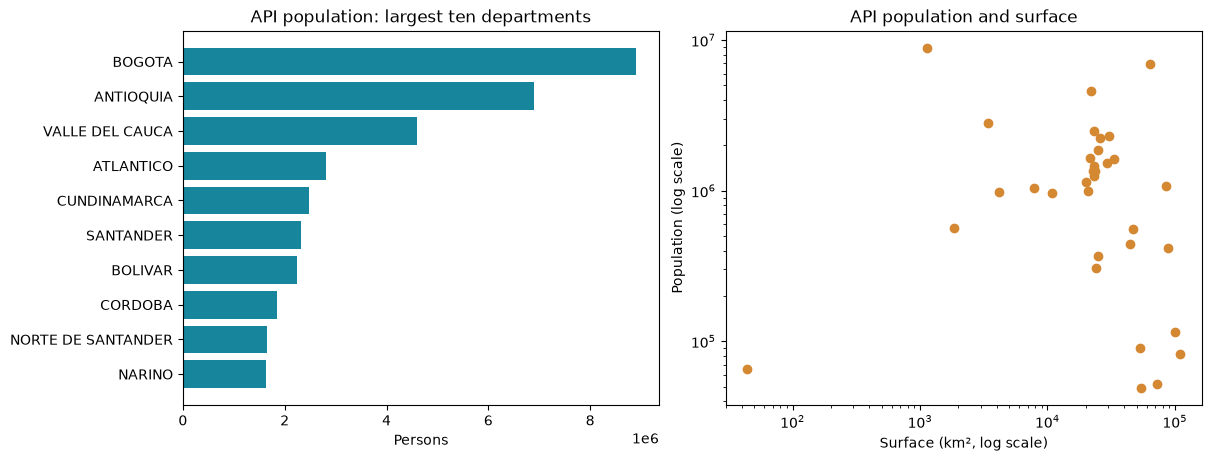

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
top_population = df_api_departments.nlargest(10, 'population').sort_values('population')
axes[0].barh(top_population['department_name'], top_population['population'], color='#17859c')
axes[0].set(title='API population: largest ten departments', xlabel='Persons')
axes[1].scatter(df_api_departments['surface'], df_api_departments['population'], color='#d48832')
axes[1].set(xscale='log', yscale='log', title='API population and surface', xlabel='Surface (km², log scale)', ylabel='Population (log scale)')
fig.savefig(EVIDENCE_DIR / 'eda_api_population_surface.png', dpi=150)
plt.show()


### 9.3 Integration findings and decisions

Department aliases must be normalized before integration: BOGOTA → BOGOTA D.C. and SAN ANDRES Y PROVIDENCIA → SAN ANDRES. The artificial SIN DEPARTAMENTO member is excluded from coverage expectations. The regional classification is checked against the same API snapshot, including Norte de Santander → Andina, Guainía → Amazonia and Vichada → Orinoquia. R3 must count the unique facility key, not one row per capacity type.

The JSON profile below records observed source metrics, the pre/post-normalization match rate and API validity checks. The department count includes Bogotá as the API reports it.

In [44]:
primary_snapshot = extract_all()
integration = profile_cross_source_integration(primary_snapshot['affiliates'], primary_snapshot['facilities'], df_api_departments)
display(pd.DataFrame([{
    'CSV departments': integration['primary_departments_count'],
    'API departments': integration['api_departments_count'],
    'Match before aliases (%)': integration['raw_match_rate_pct'],
    'Match after aliases (%)': integration['harmonized_match_rate_pct'],
}]))
profile_evidence = run_profiling()
print('Saved reproducible profile: docs/evidence/profiling/data_profiling_evidence.json')


2026-11-18 01:49:24,244 [INFO] Extracting affiliates from: C:\Users\mauri\OneDrive\Escritorio\etl\proyecto-3\etl-2026-2-ods3-salud-api-gx-airflow-streaming-kafka-\src\..\data\raw/affiliates_by_department_municipality_regime_20260906.csv


2026-11-18 01:49:24,260 [INFO] Records extracted: 3369


2026-11-18 01:49:24,261 [INFO] Extracting facilities from: C:\Users\mauri\OneDrive\Escritorio\etl\proyecto-3\etl-2026-2-ods3-salud-api-gx-airflow-streaming-kafka-\src\..\data\raw/healthcare_facilities_by_level_capacity_20260906.csv


2026-11-18 01:49:24,741 [INFO] Records extracted: 41427


2026-11-18 01:49:24,742 [INFO] Profiling cross-source integration compatibility...


,CSV departments,API departments,Match before aliases (%),Match after aliases (%)
0,33,33,93.94,100.0


... (11 outputs left out)

2026-11-18 01:49:25,568 [INFO] Profiling dataset: api_colombia_regions (6 rows, 2 columns)...


2026-11-18 01:49:25,572 [INFO] Profiling cross-source integration compatibility...


2026-11-18 01:49:25,715 [INFO] Profiling evidence written to: C:\Users\mauri\OneDrive\Escritorio\etl\proyecto-3\etl-2026-2-ods3-salud-api-gx-airflow-streaming-kafka-\src\..\docs\evidence\profiling\data_profiling_evidence.json



PROFILING SUMMARY:
  Affiliates:        3369 rows, 0 total nulls
  Facilities:        41427 rows, 195 capacity values
  API Departments:   33 records
  API Regions:       6 records
  Region mismatches: 0
  Integration Match: 100.0% matching (harmonized) / 93.94% (raw)

Saved reproducible profile: docs/evidence/profiling/data_profiling_evidence.json


## 10. From EDA to Data Quality Rules (DQ-01 → DQ-12)

The EDA above is not descriptive only: **every finding became a cleaning step and/or a
data-quality rule** enforced by the batch pipeline (`src/quality/rules.py`, executed by the
three Airflow validation gates and mirrored as Great Expectations expectations).

### 10.1 EDA findings → transformations

| # | EDA finding (observed in this notebook) | Transformation / cleanup applied |
|---|---|---|
| 1 | `NumPersonas` is stored as `object` with Spanish thousands separators (`'2.194'`, `'4.595'`) | Strip `.`, `to_numeric`, cast to `int`; drop rows `<= 0` |
| 2 | `Año` / `Mes` read as strings | Cast to `int` before building `dim_time` |
| 3 | Facilities contain **3,145 fully duplicated rows (7.59%)** | `drop_duplicates()` before aggregating capacity |
| 4 | Facilities: 26,958 nulls, but **only in optional columns** (`num nivel atencion` 60.99%, `Teléfono` 3.16%, `Gerente`, `Email`, `Dirección`); identity/capacity columns have **0 nulls** | Keep nulls only for optional contact fields; essential attributes are validated with a ≥ 99.5% threshold (DQ-04) instead of a naive 100% |
| 5 | `nit IPS` mixes digits and separators (`890,980,643`) | Strip `,` to obtain a clean numeric NIT |
| 6 | Department names appear in several spellings (`VALLE` ×126 rows instead of `VALLE DEL CAUCA`, `SAN ANDRES`, `NO APLICA`) and special districts are reported as departments (`CARTAGENA` ×3, `SANTA MARTA` ×3) | `DEPT_NORMALIZE`, `DISTRICT_TO_DEPT` and `REGION_MAP` in `src/config.py` → unified `dim_geografia` (section 5) |
| 7 | Regimen codes are a small closed set: `S` (1,124), `C` (1,122), `E` (1,115), `I` (8) | Map to `SUBSIDIZED / CONTRIBUTORY / SPECIAL / INDIVIDUAL` in `dim_regime`; the closed set becomes rule **DQ-02** |
| 8 | Affiliates CSV has 0 nulls and 0 duplicates, but the grain (dept × municipality × regime × year × month) must stay unique after integration with the API | Uniqueness of the declared fact grain → **DQ-09 / DQ-10** |

### 10.2 EDA findings → data-quality rules (executed in every DAG run)

| Rule | Layer | What the EDA motivated | GX expectation |
|---|---|---|---|
| DQ-01 | raw_affiliates | The 8 columns observed in section 2 are mandatory for every downstream KPI | `expect_table_columns_to_match_set` |
| DQ-02 | raw_affiliates | Regimen is a closed set {S, C, E, I} (finding #7) | `expect_column_values_to_be_in_set` |
| DQ-03 | raw_affiliates | `NumPersonas` needed parsing and had to be `> 0` (finding #1) | `expect_column_values_to_be_between` |
| DQ-04 | raw_facilities | Nulls only in optional columns; essential identity/capacity are 100% populated (finding #4) | `expect_column_values_to_not_be_null` (≥ 99.5%) |
| DQ-05 | raw_facilities | Installed capacity must be numeric and non-negative | `expect_column_values_to_be_between` |
| DQ-06 | raw_api_departments | Every API record must carry department name + id to be joinable | `expect_column_values_to_not_be_null` |
| DQ-07 | raw_api_departments | Official population/surface must be `> 0` to compute R6/R7 rates | `expect_column_values_to_be_between` |
| DQ-08 | integration_gate | CSV ↔ API department codes must actually match (finding #6) | `expect_integration_key_match_rate` ≥ 95% |
| DQ-09 | prepared_fact_affiliates | Declared grain must stay unique after dedup + integration (finding #8) | `expect_compound_columns_to_be_unique` |
| DQ-10 | prepared_fact_capacity | Same for capacity grain (findings #3, #8) | `expect_compound_columns_to_be_unique` |
| DQ-11 | prepared_facts | Every surrogate key must resolve in its dimension (star schema integrity) | `expect_foreign_keys_to_exist_in_dimensions` |
| DQ-12 | prepared_facts | Raw person totals must reconcile with the loaded fact within 0.01% | `expect_sum_reconciliation` |

> All 12 rules are **CRITICAL**: a violation raises `CriticalQualityError`, fails the
> validation task in Airflow (visible as a red/failed task) and **blocks the DW load**, so
> invalid data never reaches the dimensional model. Each rule is evaluated twice — with the
> native pandas implementation and with the equivalent Great Expectations expectation — and
> the gate only passes when both agree (conservative AND, see README §5).


## Summary

The executed table below is calculated from the loaded snapshots and the cleanup above.

### Actions Performed
1. Data type conversion
2. Numeric field cleanup (periods as thousand separators)
3. Duplicate removal
4. Removal of records with nulls in critical fields
5. Removal of records with invalid values (0 affiliates)
6. Clean data saved to `data/processed/`

---

### Final Star Schema (5 Dimensions)

The cleaned data feeds into a simplified star schema with **5 dimensions** (reduced from 8+):

| Dimension | Description | Source |
|-----------|-------------|--------|
| `dim_time` | Year and month | Affiliates dataset |
| `dim_geografia` | Unified geography with DANE codes + API Colombia enrichment (capital, surface, population, municipalities_count, phone_prefix, region_api) | Affiliates + Facilities + API Colombia |
| `dim_regime` | Healthcare regime (S, C, E, I) | Affiliates dataset |
| `dim_facility` | Healthcare facility with `sk_geografia` FK (replaces `sk_municipality`) | Facilities dataset |
| `dim_capacity_type` | Capacity group and description | Facilities dataset |

**Removed dimensions:** `dim_department`, `dim_municipality`, `dim_department_api` — all consolidated into the unified `dim_geografia`.

In [45]:
summary = pd.DataFrame([
    {'Dataset': 'Affiliates CSV', 'Original records': len(df_affiliates), 'Clean records': len(df_affiliates_clean), 'Removed': len(df_affiliates) - len(df_affiliates_clean)},
    {'Dataset': 'Facilities CSV', 'Original records': len(df_facilities), 'Clean records': len(df_facilities_clean), 'Removed': len(df_facilities) - len(df_facilities_clean)},
    {'Dataset': 'API departments', 'Original records': len(df_api_departments), 'Clean records': len(df_api_departments), 'Removed': 0},
    {'Dataset': 'API regions', 'Original records': len(df_api_regions), 'Clean records': len(df_api_regions), 'Removed': 0},
])
display(summary)
print('API region mappings disagree with configuration:', len(api_checks['region_mapping_mismatches']))
print('CSV departments matched after normalization:', integration['harmonized_match_rate_pct'], '%')


,Dataset,Original records,Clean records,Removed
0,Affiliates CSV,3369,3369,0
1,Facilities CSV,41427,38282,3145
2,API departments,33,33,0
3,API regions,6,6,0


API region mappings disagree with configuration: 0
CSV departments matched after normalization: 100.0 %
